# Retail Supply Chain Analytics — Demand Forecasting

**Goal:** Forecast monthly units sold for five product categories and evaluate whether Holt–Winters improves on naive forecasting.

**Dataset:** `retail_supply_chain_clean.csv` (2023–2025).
Forecasts for January–March 2026 are projections from the dataset cutoff, **not current-date forecasts**.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose

sns.set_theme(style="whitegrid", palette="Set2")
DATA_PATH = Path("../data/processed/retail_supply_chain_clean.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../retail_supply_chain_clean.csv")  # if notebook is run next to uploaded CSV
REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(DATA_PATH, parse_dates=["Date"])
print("Shape:", df.shape, "| Range:", df.Date.min(), "to", df.Date.max())
print("Categories:", sorted(df.Product_Category.dropna().unique()))

Shape: (200000, 48) | Range: 2023-01-01 00:00:00 to 2025-12-30 00:00:00
Categories: ['Electronics', 'Fashion', 'Food', 'Health', 'Home']


## 1. Data checks and monthly aggregation


In [2]:
required = ["Date", "Product_Category", "Units_Sold"]
assert not df[required].isna().any().any(), "Missing required values: investigate first"
assert (df["Units_Sold"] >= 0).all(), "Negative sales: investigate returns/adjustments"
print("Full-row duplicates:", df.duplicated().sum())
print("Unique product IDs:", df["Product_ID"].nunique() if "Product_ID" in df else "not provided")

monthly = (df.groupby([pd.Grouper(key="Date", freq="ME"), "Product_Category"])["Units_Sold"]
             .sum().unstack().asfreq("ME"))
print("Months:", len(monthly), "| Start:", monthly.index.min(), "| End:", monthly.index.max())
print("Missing category-months:", int(monthly.isna().sum().sum()))
if monthly.isna().any().any():
    raise ValueError("Missing category-month combinations; resolve before forecasting.")
display(monthly.head())

Full-row duplicates: 0
Unique product IDs: 200000
Months: 36 | Start: 2023-01-31 00:00:00 | End: 2025-12-31 00:00:00
Missing category-months: 0


Product_Category,Electronics,Fashion,Food,Health,Home
Date,,,,,
2023-01-31,2909169,2911817,2947095,3162192,2856296
2023-02-28,2705764,2478276,2564876,2606134,2668076
2023-03-31,2721535,2774268,2867577,2783138,2729153
2023-04-30,2496378,2694017,2702371,2648302,2832481
2023-05-31,2965103,2751063,2908215,2862583,2818917


## 2. Exploratory demand trends

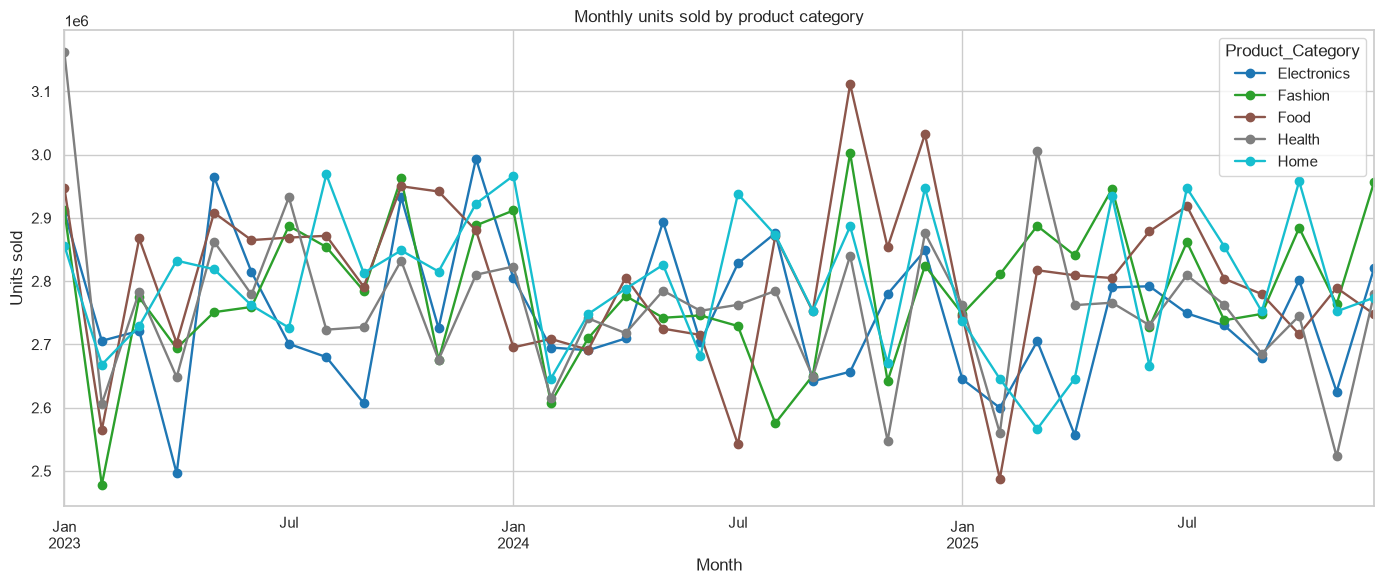

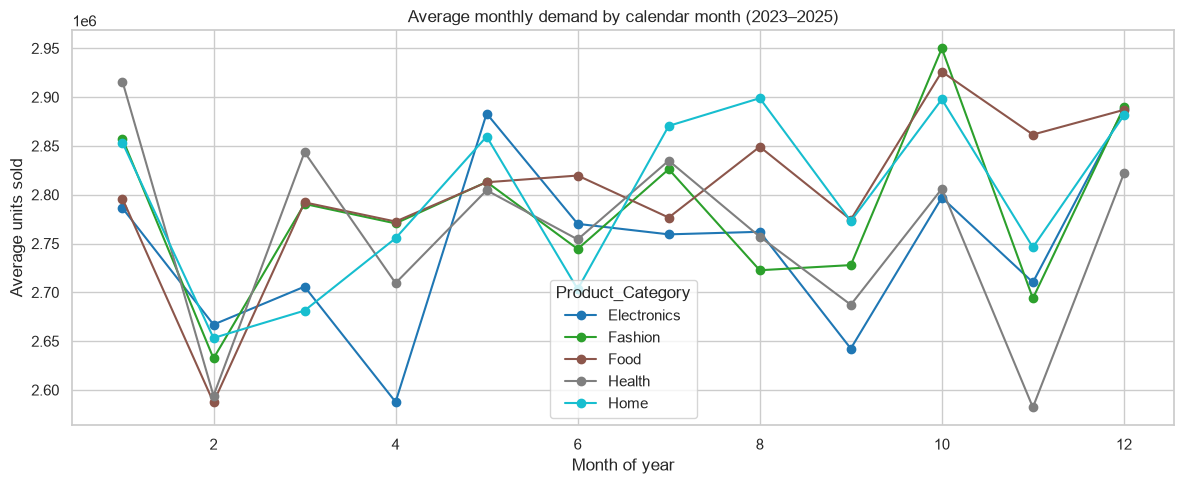

In [3]:
ax = monthly.plot(figsize=(14, 6), marker="o", linewidth=1.7, colormap="tab10")
ax.set(title="Monthly units sold by product category", xlabel="Month", ylabel="Units sold")
plt.tight_layout()
plt.savefig(REPORT_DIR / "monthly_demand_by_category.png", dpi=200, bbox_inches="tight")
plt.show()

seasonal_profile = monthly.groupby(monthly.index.month).mean()
seasonal_profile.index.name = "Month of year"
ax = seasonal_profile.plot(figsize=(12, 5), marker="o", colormap="tab10")
ax.set(title="Average monthly demand by calendar month (2023–2025)", ylabel="Average units sold")
plt.tight_layout()
plt.savefig(REPORT_DIR / "seasonal_profile.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Seasonal decomposition (exploratory only)


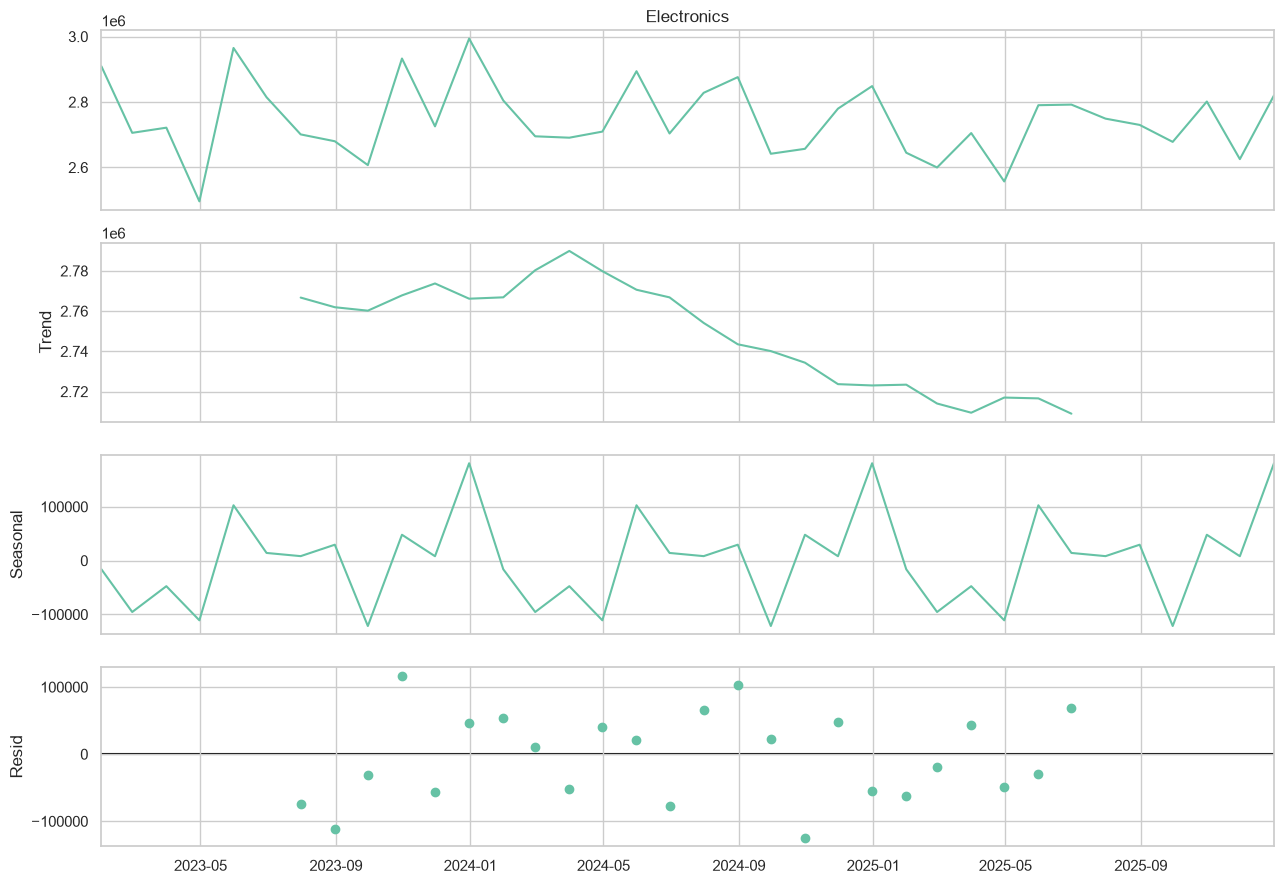

In [4]:
series = monthly["Electronics"].astype(float)
if len(series) >= 24:
    decomposition = seasonal_decompose(series, model="additive", period=12)
    fig = decomposition.plot()
    fig.set_size_inches(13, 9)
    fig.tight_layout()
    fig.savefig(REPORT_DIR / "electronics_decomposition.png", dpi=200, bbox_inches="tight")
    plt.show()

## 4. Forecasting methods and evaluation


In [5]:
def predict_method(train, horizon, method):
    train = train.astype(float)
    if method == "Naive":
        values = np.repeat(train.iloc[-1], horizon)
    elif method == "Seasonal naive":
        if len(train) < 12:
            raise ValueError("Seasonal naive needs 12 months")
        values = np.resize(train.iloc[-12:].to_numpy(), horizon)
    elif method in ("Holt trend", "Holt-Winters seasonal"):
        seasonal = method == "Holt-Winters seasonal"
        if seasonal and len(train) < 24:
            raise ValueError("Seasonal Holt-Winters requires >=24 months in this notebook")
        fit = ExponentialSmoothing(
            train, trend="add", seasonal="add" if seasonal else None,
            seasonal_periods=12 if seasonal else None,
            initialization_method="estimated"
        ).fit(optimized=True)
        values = np.asarray(fit.forecast(horizon))
    else:
        raise ValueError(method)
    idx = pd.date_range(train.index[-1] + pd.offsets.MonthEnd(1), periods=horizon, freq="ME")
    return pd.Series(np.maximum(values, 0), index=idx, name=method)

def metrics(actual, predicted):
    a = np.asarray(actual, dtype=float)
    p = np.asarray(predicted, dtype=float)
    denom = np.abs(a).sum()
    return {"MAE": mean_absolute_error(a, p),
            "RMSE": np.sqrt(mean_squared_error(a, p)),
            "WAPE_pct": 100 * np.abs(a-p).sum()/denom if denom else np.nan}

METHODS = ["Naive", "Seasonal naive", "Holt trend", "Holt-Winters seasonal"]

## 5. Fixed holdout: train through December 2024, test January–December 2025
The seasonal model uses 24 training observations. 

In [6]:
holdout_rows = []
holdout_predictions = {}
for category in monthly.columns:
    series = monthly[category].astype(float)
    train = series.loc[:"2024-12-31"]
    test = series.loc["2025-01-01":"2025-12-31"]
    assert len(train) == 24 and len(test) == 12, f"Unexpected coverage for {category}"
    for method in METHODS:
        try:
            pred = predict_method(train, len(test), method)
            score = metrics(test, pred)
            holdout_rows.append({"Category": category, "Model": method, **score})
            holdout_predictions[(category, method)] = pred
        except (ValueError, RuntimeError, np.linalg.LinAlgError) as exc:
            print(f"Skipped {category} / {method}: {exc}")
holdout_results = pd.DataFrame(holdout_rows).sort_values(["Category", "WAPE_pct"])
display(holdout_results.round(2))
holdout_results.to_csv(REPORT_DIR / "forecast_holdout_metrics.csv", index=False)

,Category,Model,MAE,RMSE,WAPE_pct
2,Electronics,Holt trend,83892.78,106378.97,3.10
3,Electronics,Holt-Winters seasonal,96692.12,105934.19,3.57
1,Electronics,Seasonal naive,100155.83,112136.11,3.70
0,Electronics,Naive,140775.67,163615.62,5.20
6,Fashion,Holt trend,68132.15,79009.39,2.41
4,Fashion,Naive,69976.83,78306.00,2.48
7,Fashion,Holt-Winters seasonal,130527.53,158057.04,4.62
5,Fashion,Seasonal naive,132751.92,142807.86,4.70
11,Food,Holt-Winters seasonal,98310.63,117922.46,3.54
10,Food,Holt trend,110328.97,143598.08,3.98


## 6. Visualize model comparison and the Electronics holdout

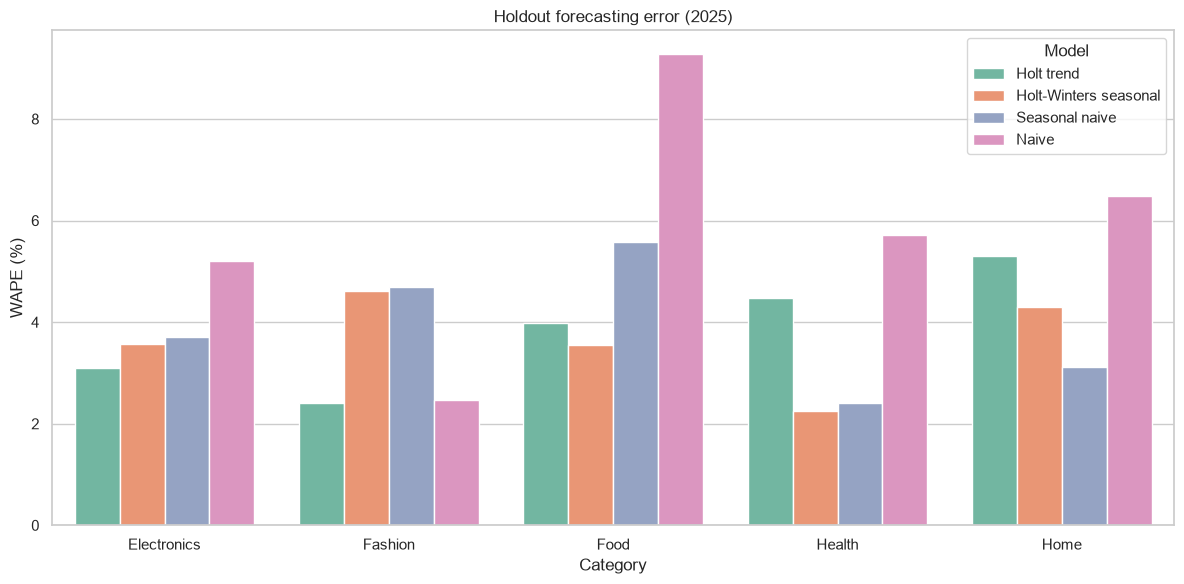

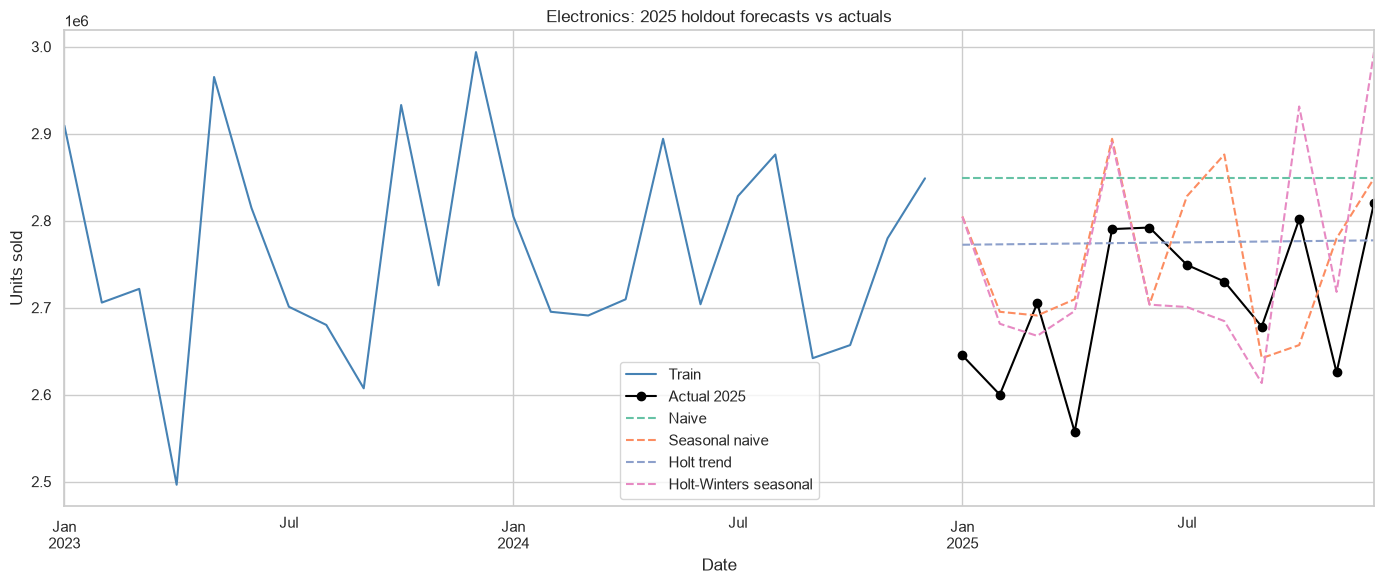

In [7]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=holdout_results, x="Category", y="WAPE_pct", hue="Model", ax=ax)
ax.set(title="Holdout forecasting error (2025)", ylabel="WAPE (%)", xlabel="Category")
plt.tight_layout()
plt.savefig(REPORT_DIR / "model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

category = "Electronics"
fig, ax = plt.subplots(figsize=(14, 6))
monthly[category].loc[:"2024-12-31"].plot(ax=ax, label="Train", color="steelblue")
monthly[category].loc["2025"].plot(ax=ax, label="Actual 2025", color="black", marker="o")
for method in METHODS:
    if (category, method) in holdout_predictions:
        holdout_predictions[(category, method)].plot(ax=ax, label=method, linestyle="--")
ax.set(title="Electronics: 2025 holdout forecasts vs actuals", ylabel="Units sold")
ax.legend()
plt.tight_layout()
plt.savefig(REPORT_DIR / "electronics_holdout.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Rolling-origin backtest: three-month forecasts


In [8]:
rolling_rows = []
HORIZON = 3
for category in monthly.columns:
    series = monthly[category].astype(float)
    for cutoff in range(24, len(series)-HORIZON+1):
        train = series.iloc[:cutoff]
        actual = series.iloc[cutoff:cutoff+HORIZON]
        for method in METHODS:
            try:
                pred = predict_method(train, HORIZON, method)
                rolling_rows.append({
                    "Category": category, "Model": method,
                    "Train_end": train.index[-1], **metrics(actual, pred)
                })
            except (ValueError, RuntimeError, np.linalg.LinAlgError) as exc:
                print(f"Skipped {category} / {method} / {train.index[-1].date()}: {exc}")
rolling = pd.DataFrame(rolling_rows)
rolling_summary = (rolling.groupby(["Category", "Model"], as_index=False)
                   .agg(Mean_MAE=("MAE", "mean"), Mean_RMSE=("RMSE", "mean"),
                        Mean_WAPE_pct=("WAPE_pct", "mean"), Origins=("Train_end", "count")))
display(rolling_summary.sort_values(["Category", "Mean_WAPE_pct"]).round(2))
rolling.to_csv(REPORT_DIR / "rolling_origin_results.csv", index=False)
rolling_summary.to_csv(REPORT_DIR / "rolling_origin_summary.csv", index=False)

,Category,Model,Mean_MAE,Mean_RMSE,Mean_WAPE_pct,Origins
0,Electronics,Holt trend,77543.82,86234.74,2.88,10
1,Electronics,Holt-Winters seasonal,85105.57,88616.75,3.14,10
3,Electronics,Seasonal naive,99329.00,110136.41,3.66,10
2,Electronics,Naive,103901.87,109412.93,3.83,10
4,Fashion,Holt trend,71625.51,82070.09,2.54,10
6,Fashion,Naive,88902.87,102973.26,3.15,10
7,Fashion,Seasonal naive,128831.13,138729.85,4.56,10
5,Fashion,Holt-Winters seasonal,129365.80,138466.06,4.57,10
8,Food,Holt trend,74453.98,91757.78,2.70,10
9,Food,Holt-Winters seasonal,113580.54,132368.25,4.08,10


## 8. Refit and project January–March 2026


,Date,Product_Category,Selected_Model,Forecast_Units
0,2026-01-31,Electronics,Holt trend,2.725371e+06
1,2026-02-28,Electronics,Holt trend,2.724414e+06
2,2026-03-31,Electronics,Holt trend,2.723458e+06
3,2026-01-31,Fashion,Holt trend,2.864861e+06
4,2026-02-28,Fashion,Holt trend,2.870195e+06
5,2026-03-31,Fashion,Holt trend,2.875530e+06
6,2026-01-31,Food,Holt trend,2.817076e+06
7,2026-02-28,Food,Holt trend,2.818492e+06
8,2026-03-31,Food,Holt trend,2.819908e+06
9,2026-01-31,Health,Seasonal naive,2.762469e+06


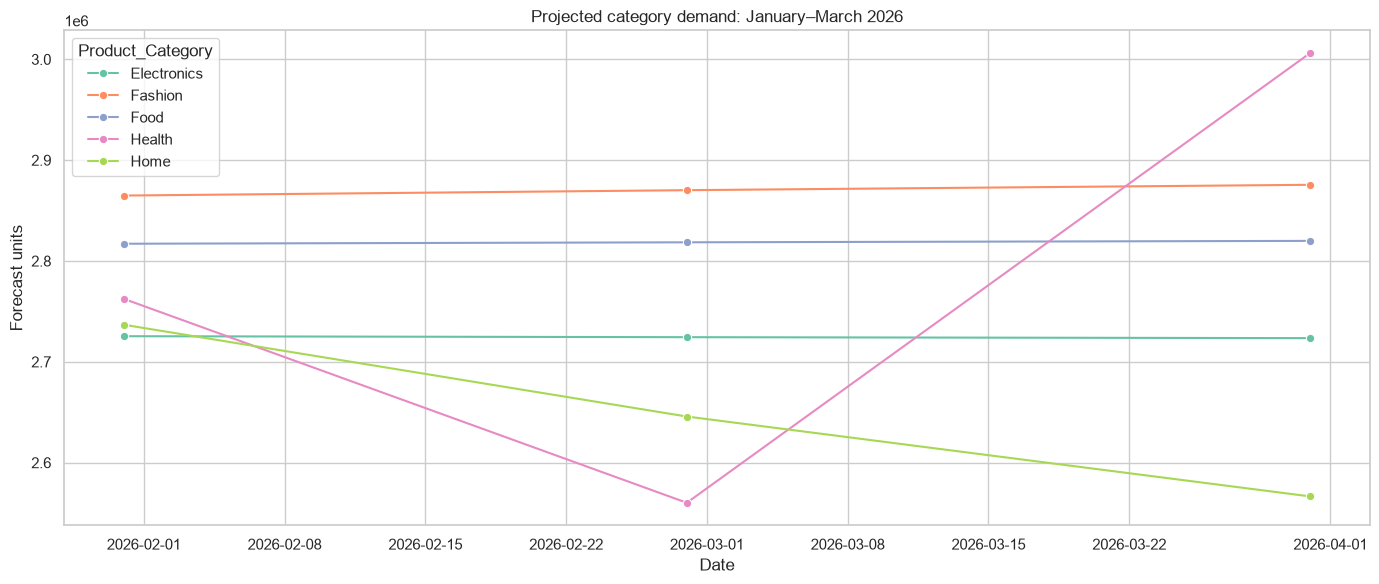

In [9]:
best_models = (rolling_summary.sort_values(["Category", "Mean_MAE"])
               .drop_duplicates("Category").set_index("Category")["Model"])
future_rows = []
for category in monthly.columns:
    method = best_models[category]
    pred = predict_method(monthly[category], 3, method)
    for date, value in pred.items():
        future_rows.append({"Date": date, "Product_Category": category,
                            "Selected_Model": method, "Forecast_Units": float(value)})
future = pd.DataFrame(future_rows)
display(future)
future.to_csv(REPORT_DIR / "category_demand_forecast_2026_Q1.csv", index=False)

fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(data=future, x="Date", y="Forecast_Units", hue="Product_Category", marker="o", ax=ax)
ax.set(title="Projected category demand: January–March 2026", ylabel="Forecast units")
plt.tight_layout()
plt.savefig(REPORT_DIR / "forecast_2026_Q1.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Business interpretation and limitations


### 9.1 Key Forecasting Findings

The demand forecasting analysis evaluated multiple statistical forecasting approaches across five retail product categories: Electronics, Fashion, Food, Health, and Home.

Models were assessed using a chronological holdout period and rolling-origin backtesting, with Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Weighted Absolute Percentage Error (WAPE) used to measure predictive performance.

The results demonstrate that **forecasting performance varies across product categories**, highlighting the importance of category-specific model selection rather than applying a single forecasting method across the entire retail portfolio.

Based on the rolling-origin evaluation, the best-performing models were:

| Product Category | Best Model | Mean WAPE |
|---|---|---|
| Electronics | Holt Trend | 2.88% |
| Fashion | Holt Trend | 2.54% |
| Food | Holt Trend | 2.70% |
| Health | Seasonal Naive | 2.39% |
| Home | Seasonal Naive | 2.70% |

Holt's linear trend model achieved the lowest average forecasting errors for Electronics, Fashion, and Food, while the seasonal naive model performed best for Health and Home.

These findings suggest that **more complex seasonal models do not necessarily produce more accurate forecasts**. Simpler approaches can provide competitive or superior performance, depending on the characteristics of the demand series.

### 9.2 Business Implications

**1. Improved Inventory Planning**

Demand forecasts can support more informed inventory decisions by providing estimates of future product requirements.

Category-level predictions may help supply chain managers anticipate changes in demand, review inventory allocations, and coordinate replenishment activities.

**2. Reduced Stockout and Overstock Risks**

Forecasting can contribute to identifying potential mismatches between expected demand and available inventory.

When combined with current stock levels, supplier lead times, and safety stock policies, demand predictions can support the identification of products at risk of stockouts or excessive inventory.

However, these operational benefits have not yet been directly measured in this analysis.

**3. Category-Specific Forecasting Strategies**

The evaluation suggests that a single forecasting approach may not be optimal for every product category.

A category-specific forecasting framework would allow businesses to select models based on historical predictive performance, improving the adaptability of demand planning processes.

**4. Data-Driven Supply Chain Decision-Making**

The forecasting pipeline provides a reproducible foundation for demand monitoring and planning.

By integrating forecast outputs into a business intelligence dashboard, decision-makers could compare historical demand, expected future demand, and forecasting accuracy across categories.

### 9.3 Limitations

Despite the encouraging forecasting results, several limitations should be considered.

**Limited Historical Coverage**

The dataset covers January 2023 through December 2025, providing approximately three years of monthly observations. Although sufficient to experiment with annual seasonality, this relatively short history limits the ability to evaluate long-term demand patterns and changes in seasonal behavior.

**Aggregated Demand**

Forecasting was performed at the product-category level rather than at the individual SKU level.

Category-level aggregation can smooth fluctuations in individual product demand, potentially resulting in lower forecasting errors. Consequently, the reported performance should not be interpreted as equivalent to SKU-level forecasting accuracy.

**Limited Explanatory Variables**

The forecasting models primarily rely on historical sales volumes. They do not explicitly incorporate external demand drivers such as promotions, holidays, pricing changes, competitor activity, or economic conditions.

These factors may influence future demand and could improve forecasting performance if suitable historical data becomes available.

**Uncertainty and Forecast Reliability**

The reported WAPE values summarize historical forecasting performance and do not guarantee equivalent accuracy on future observations.

Furthermore, the rolling-origin evaluation uses overlapping forecast windows, meaning the evaluation errors are not statistically independent.

The forecasts generated for January–March 2026 represent projections based on historical observations ending in December 2025. They have not been validated against actual sales from those months.

**Sales Versus True Demand**

Units sold are used as a proxy for demand. However, observed sales may underestimate true customer demand when products are unavailable or stockouts prevent purchases.

As a result, forecasting sales volumes does not necessarily capture all unmet demand.

### 9.4 Recommendations and Future Improvements

Future development of this project could focus on:

1. **SKU-Level Forecasting:** Extend the analysis to individual products where sufficient historical observations are available.
2. **Additional Predictive Models:** Evaluate SARIMA, gradient boosting, and other forecasting approaches against the established statistical baselines.
3. **External Features:** Incorporate relevant pricing, promotional, and calendar information where available.
4. **Forecast Uncertainty:** Estimate prediction intervals to communicate the uncertainty associated with future demand.
5. **Inventory Optimization:** Combine demand forecasts with supplier lead times, inventory levels, and service-level targets to estimate reorder points and safety stock.
6. **Interactive Dashboard:** Develop a Streamlit or Power BI dashboard for visualizing demand trends, forecasting performance, and inventory indicators.

### 9.5 Conclusion

This analysis demonstrates the value of systematic model evaluation for retail demand forecasting.

Rather than relying on a single forecasting algorithm, the results support selecting forecasting methods according to product-category characteristics and historical predictive performance.

The relatively low forecasting errors observed during backtesting provide an encouraging starting point for demand planning applications. Nevertheless, further validation and more granular data would be necessary before using these predictions for operational inventory decisions.

**Overall, the project establishes a reproducible forecasting framework that can serve as a foundation for inventory optimization, supply chain analytics, and data-driven retail decision-making.**